In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/Bachelorarbeit/projects'    # folder with your .py modules
OUT     = '/content/drive/MyDrive/vae_results/flatvae/_with_larger_'    # where the PDFs go

import os, sys, gc, time
os.chdir(PROJECT); sys.path.insert(0, PROJECT)
os.makedirs(OUT, exist_ok=True)

import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
plt.rcParams.update({
    "axes.labelsize": 14,    # x/y axis labels
    "xtick.labelsize": 12,   # tick numbers
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.titlesize": 15,
})
DEV  = "cuda" if torch.cuda.is_available() else "cpu"
GRID, CHUNK, SEED = 100, 64, 10
print(f"torch {torch.__version__}  train on {DEV}  (diagnostics on cpu)")
if DEV != "cuda":
    print("!! Runtime > Change runtime type > T4 GPU")

from vaediagnostic import run_diagnostics, _np
from datasets import make_torus_dataset, make_plane_dataset, make_plane_dataset_old
try:
    from bin_scripts.sphere_data import make_sphere_dataset_try3
except ModuleNotFoundError as e:
    print(f"!! bin_scripts missing ({e}) -- falling back to a DIFFERENT dataset")
    from datasets import make_sphere_dataset_new as make_sphere_dataset_try3

Mounted at /content/drive
torch 2.11.0+cu128  train on cuda  (diagnostics on cpu)


In [2]:
class simpleVAE(nn.Module):
    def __init__(self, data_dim=2, latent_dim=2, hidden=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(data_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
        )
        self.mu = nn.Linear(hidden, latent_dim)
        self.logvar = nn.Linear(hidden, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, data_dim),
        )

    def encode(self, data):
        h = self.encoder(data)          # one backbone pass, not two
        return self.mu(h), self.logvar(h)

    def reparametrize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, theta):
        return self.decoder(theta)

    def forward(self, data):
        mu, logvar = self.encode(data)
        return self.decode(self.reparametrize(mu, logvar)), mu, logvar


def elbo(x_recon, x, mu, logvar, beta=1.0):
    recon = ((x_recon - x) ** 2).sum(dim=1).mean()
    kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1).mean()
    return recon + beta * kl, recon.item(), kl.item()


def train(epochs=400, lr=1e-3, beta=1.0, dataset=None, device=DEV,
          seed=SEED, log_every=100, eval_every=100, val_n=2000, val_seed=1234):
    if seed is not None:
        torch.manual_seed(seed)

    imgs, angles = dataset()
    data = torch.as_tensor(imgs, dtype=torch.float32, device=device)
    if data.dim() > 2:
        data = data.flatten(1)

    val_imgs, val_ang = dataset(n=val_n, seed=val_seed)
    val = torch.as_tensor(val_imgs, dtype=torch.float32, device=device)
    if val.dim() > 2:
        val = val.flatten(1)

    model = simpleVAE(data_dim=data.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    curve = []
    for ep in range(epochs):
        opt.zero_grad(set_to_none=True)
        x_recon, mu, logvar = model(data)
        loss, r, k = elbo(x_recon, data, mu, logvar, beta)
        loss.backward()
        opt.step()

        if eval_every and (ep % eval_every == 0 or ep == epochs - 1):
            e_tr = per_sample_err(model, data)
            e_va = per_sample_err(model, val)
            curve.append(dict(epoch=ep, loss=loss.item(), recon=r, kl=k,
                              train=e_tr.mean(), val=e_va.mean(),
                              val_median=np.median(e_va),
                              val_p95=np.percentile(e_va, 95)))
            model.train()

        if log_every and (ep % log_every == 0 or ep == epochs - 1):
            print(f"epoch {ep:5d}  loss={loss.item():.4f}  "
                  f"recon={r:.4f}  kl={k:.4f}")

    return model, data, angles, curve, (val, np.asarray(val_ang))

In [3]:
@torch.no_grad()
def _recon(model, x):
    enc = model.encode(x)
    mu = enc[0] if isinstance(enc, tuple) else enc
    return  model.decode(mu)

@torch.no_grad()
def per_sample_err(model, x, batch=4096):
    model.eval()
    p = next(model.parameters())
    x = x.to(device=p.device, dtype=p.dtype)
    return torch.cat([((x[i:i+batch] - _recon(model, x[i:i+batch]))**2).sum(1)
                      for i in range(0, x.shape[0], batch)]).cpu().numpy()

def make_val(data_fn, n=2000, seed=1234):
    p = None
    imgs, ang = data_fn(n=n, seed=seed)
    return torch.as_tensor(imgs, dtype=torch.float32), np.asarray(ang)

def report(name, model, data, val_x, val_ang, n_worst=200, ax_hist=None, ax_map=None):
    e_tr = per_sample_err(model, data)
    e_va = per_sample_err(model, val_x)
    print(f"{name:22s} train {e_tr.mean():.4f}  held-out {e_va.mean():.4f}  "
          f"gap {100*(e_va.mean()/e_tr.mean()-1):5.1f}%   |  held-out "
          f"median {np.median(e_va):.4f}  95th {np.percentile(e_va,95):.4f}  "
          f"max {e_va.max():.4f}  mean/median {e_va.mean()/np.median(e_va):.2f}")

    if ax_hist is not None:
        ax_hist.hist(np.log10(e_va + 1e-12), bins=60, color="0.4")
        ax_hist.axvline(np.log10(np.median(e_va)), color="crimson", lw=1.5)
        ax_hist.set_title(name, fontsize=9)
        ax_hist.set_xlabel(r"$\log_{10}$ per-sample error")

    if ax_map is not None:
        bad = np.argsort(e_va)[-n_worst:]
        ax_map.scatter(val_ang[:, 0], val_ang[:, 1], s=2, c="0.85", linewidths=0)
        ax_map.scatter(val_ang[bad, 0], val_ang[bad, 1], s=6, c="crimson", linewidths=0)
        ax_map.set_aspect("equal")
        ax_map.set_title(f"{name}: worst {n_worst}", fontsize=9)
    return e_tr, e_va

In [4]:
def plot_worst_points(model, data, angles, val_x, val_ang, n_worst=500,
                      n_points=4000, seed=0, s=4, cyclic=True, save=None,
                      panel_labels=("a)", "b)"), label_size=14, show=True):

    e_va = per_sample_err(model, val_x)
    bad = np.argsort(e_va)[-n_worst:]

    with torch.no_grad():
        p = next(model.parameters())
        mu_tr = _np(model.encode(data.to(device=p.device, dtype=p.dtype))[0])
        mu_bad = _np(model.encode(val_x[bad].to(device=p.device, dtype=p.dtype))[0])

    true = _np(angles)
    val_ang = np.asarray(val_ang)

    n = min(n_points, mu_tr.shape[0])
    idx = np.random.default_rng(seed).choice(mu_tr.shape[0], size=n, replace=False)
    mu_tr, true = mu_tr[idx], true[idx]

    if cyclic:
        c_bg, cmap, vmin, vmax = np.mod(true[:, 0], 2*np.pi), "hsv", 0.0, 2*np.pi
    else:
        c_bg, cmap, vmin, vmax = true[:, 0], "viridis", None, None

    fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))

    sc = ax[0].scatter(mu_tr[:, 0], mu_tr[:, 1], s=s, c=c_bg, cmap=cmap,
                       vmin=vmin, vmax=vmax, linewidths=0, alpha=0.75)
    ax[0].scatter(mu_bad[:, 0], mu_bad[:, 1], s=3*s, c="black", linewidths=0,
                  label=f"worst {n_worst} val")
    ax[0].set_aspect("equal")
    ax[0].set_xlabel(rf"$\theta_1$"); ax[0].set_ylabel(rf"$\theta_2$")
    ax[0].legend( loc="best")
    fig.colorbar(sc, ax=ax[0], fraction=0.046, pad=0.02,
                 label=r"true $\gamma_1$")

    ax[1].scatter(val_ang[:, 0], val_ang[:, 1], s=2, c="0.85", linewidths=0)
    ax[1].scatter(val_ang[bad, 0], val_ang[bad, 1], s=3*s, c="black",
                  linewidths=0)
    ax[1].set_aspect("equal")
    ax[1].set_xlabel(r"true $\gamma_1$"); ax[1].set_ylabel(r"true $\gamma_2$")

    for a, lab in zip(ax, panel_labels):
        a.text(-0.12, 1.02, lab, transform=a.transAxes, fontsize=label_size,
               fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    if save:
        stem, ext = os.path.splitext(save)
        ext = ext or ".pdf"
        fig.savefig(f"{stem}_worst{ext}", dpi=150, bbox_inches="tight")
    if not show:
        plt.close(fig)

    print(f"worst {n_worst}: err {e_va[bad].min():.3f}..{e_va[bad].max():.3f}   "
          f"median all {np.median(e_va):.3f}   "
          f"they carry {100*e_va[bad].sum()/e_va.sum():.1f}% of total error")
    return fig, bad, e_va

In [5]:
import pandas as pd

def run(fname, dataset, epochs, cyclic, label):
    print(f"\n=== {fname}  ({label})")
    t0 = time.time()
    model, data, angles, curve, (val_x, val_ang) = train(epochs=epochs, dataset=dataset)
    print(f"    trained in {time.time()-t0:.0f}s")

    # curvature_map hardcodes device="cpu"; move both back so nothing
    # inside it lands on a mismatched device
    model, data = model.cpu(), data.cpu()

    out = os.path.join(OUT, fname)
    figs = run_diagnostics(model, data, angles, grid=GRID, chunk=CHUNK,
                           fname=out, cyclic=cyclic)
    stem, ext = os.path.splitext(out); ext = ext or ".pdf"
    print(f"    wrote {os.path.basename(stem)}_latent{ext} and "
          f"{os.path.basename(stem)}_curvature{ext}")
    print(f"    done in {time.time()-t0:.0f}s")
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return model, data, angles, curve, (val_x, np.asarray(val_ang))


In [6]:
def run_gb(fname, dataset, epochs, label, gb_metric="fisher", gb_pad=0.05,
           gb_n_r=64, gb_n_theta=128, gb_n_bdry=512, gb_refine=True,
           plot=True):
    """Train, then Gauss-Bonnet only. No latent or curvature-map figures."""
    print(f"\n=== {fname}  ({label})")
    t0 = time.time()
    model, data, angles, curve, (val_x, val_ang) = train(epochs=epochs, dataset=dataset)
    print(f"    trained in {time.time()-t0:.0f}s")

    model, data = model.cpu(), data.cpu()
    model = model.double().eval()
    mu = _encode_all(model, data)

    if mu.shape[1] != 2:
        print(f"    [gb] latent dim {mu.shape[1]} != 2 -- no R^2 disk; skipping")
        return model, mu, None

    metric = gb_metric
    if metric == "fisher" and not (hasattr(model, "log_sigma_x")
                                   and hasattr(model, "data_dim")):
        print("    [gb] no log_sigma_x/data_dim -> pullback metric J^T J")
        metric = "pullback"

    c, R = disk_from_codes(mu, pad=gb_pad)
    stem, ext = os.path.splitext(os.path.join(OUT, fname))
    ext = ext or ".pdf"
    gb_fname = f"{stem}_gaussbonnet{ext}" if plot else None

    if metric == "fisher":
        gb = fisher_gauss_bonnet_disk(model, c, R, n_r=gb_n_r,
                                      n_theta=gb_n_theta, n_bdry=gb_n_bdry,
                                      chunk=CHUNK, refine=gb_refine,
                                      fname=gb_fname)
    else:
        gb = gauss_bonnet_vae(model, mu_codes=mu, center=c, radius=R,
                              n_r=gb_n_r, n_theta=gb_n_theta,
                              n_bdry=gb_n_bdry, chunk=CHUNK,
                              metric="pullback", refine=gb_refine,
                              fname=gb_fname)

    print(f"    done in {time.time()-t0:.0f}s")
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return model, mu, gb

In [7]:
def plot_curve(curve, fname, title=None, panel_labels=("a)", "b)"),
               label_size=14, show=True):
    c = pd.DataFrame(curve)
    stem, ext = os.path.splitext(fname)
    ext = ext or ".pdf"

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

    ax[0].plot(c.epoch, c.train, label="train", color="0.3")
    ax[0].plot(c.epoch, c.val, label="validation mean", color="crimson")
    ax[0].plot(c.epoch, c.val_median, "--", label="validation median",
               color="crimson", alpha=0.6)
    ax[0].set_yscale("log")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("reconstruction error")
    ax[0].legend()

    ax[1].plot(c.epoch, c.val / c.train, color="0.3", label="val / train")
    ax[1].plot(c.epoch, c.val / c.val_median, color="steelblue",
               label="mean / median (validation)")
    ax[1].axhline(1.0, color="0.7", lw=1)
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("ratio")
    ax[1].legend()

    for a, lab in zip(ax, panel_labels):
        a.text(-0.12, 1.02, lab, transform=a.transAxes, fontsize=label_size,
               fontweight="bold", va="bottom", ha="left")
    if title:
        fig.suptitle(title, fontsize=10)

    fig.tight_layout()
    fig.savefig(f"{stem}_traincurve{ext}", dpi=150, bbox_inches="tight")
    c.to_csv(f"{stem}_traincurve.csv", index=False)
    if not show:
        plt.close(fig)
    return fig, c

In [8]:
from vaediagnostic import (
    gauss_bonnet_disk, gauss_bonnet_vae, fisher_gauss_bonnet_disk,
    disk_from_codes, pullback_metric_fn, plot_gauss_bonnet,
    gauss_bonnet_selftest,
)
def gb(model, data=None, mu=None, center=None, radius=None, pad=0.05,
       n_r=64, n_theta=128, n_bdry=512, chunk=64, refine=True, batch=4096):
    """Gauss-Bonnet on the disk enclosing the latent codes. Prints, returns dict."""
    model = model.cpu().double().eval()

    # The disk has to be placed somewhere. Unless you name centre/radius
    # yourself, that means encoding the data to see where the codes are --
    # training tells the model nothing about which region you want tested.
    if center is None or radius is None:
        if mu is None:
            if data is None:
                raise ValueError("pass data, or mu, or an explicit center+radius")
            data = data.cpu().double()
            with torch.no_grad():
                mu = torch.cat([model.encode(data[i:i + batch])[0]
                                for i in range(0, data.shape[0], batch)], dim=0)
        if mu.shape[1] != 2:
            print(f"latent dim {mu.shape[1]} != 2 -- no R^2 disk")
            return None
        c, R = disk_from_codes(mu, pad=pad)
        center = c if center is None else center
        radius = R if radius is None else radius

    if hasattr(model, "log_sigma_x") and hasattr(model, "data_dim"):
        return fisher_gauss_bonnet_disk(model, center, radius, n_r=n_r,
                                        n_theta=n_theta, n_bdry=n_bdry,
                                        chunk=chunk, refine=refine)
    return gauss_bonnet_vae(model, mu_codes=mu, center=center, radius=radius,
                            n_r=n_r, n_theta=n_theta, n_bdry=n_bdry,
                            chunk=chunk, metric="pullback", refine=refine)


=== smoketest  (smoketest)
epoch     0  loss=52.1704  recon=52.1580  kl=0.0124
epoch    49  loss=23.6915  recon=23.0480  kl=0.6435
    trained in 8s
  |K|  : median 1.921e-01   max 9.591e-01
  sqrt(det g): median 8.185e-01   max 1.444e+00
    wrote smoketest_latent.pdf and smoketest_curvature.pdf
    done in 27s
   epoch       loss      recon        kl      train        val  val_median  \
0      0  52.170368  52.157955  0.012414  39.878624  39.894978   39.949738   
1     49  23.691481  23.047981  0.643500  22.139645  22.142155   22.299156   

     val_p95  
0  41.546463  
1  24.062973  


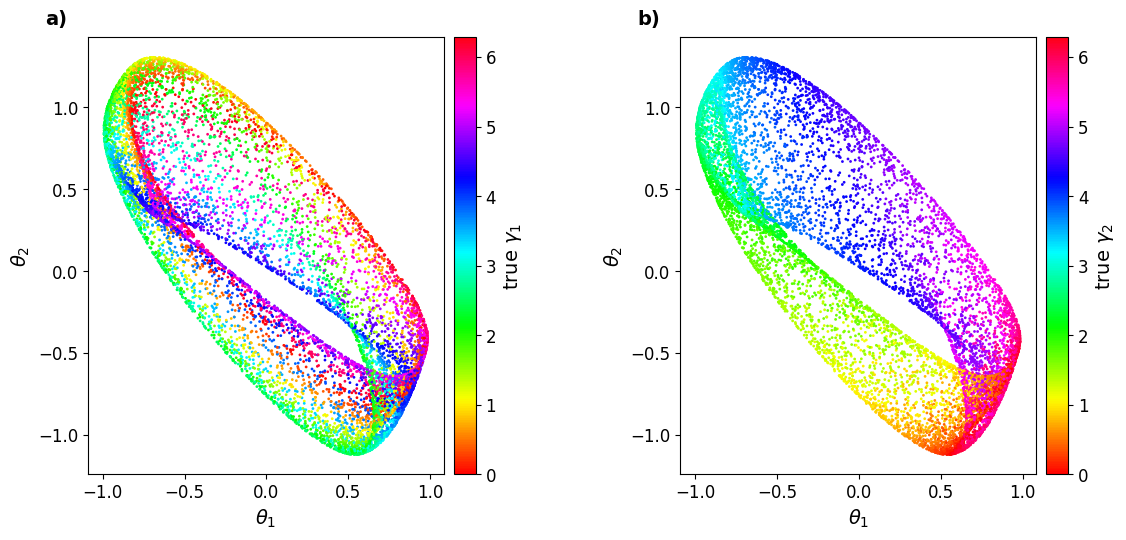

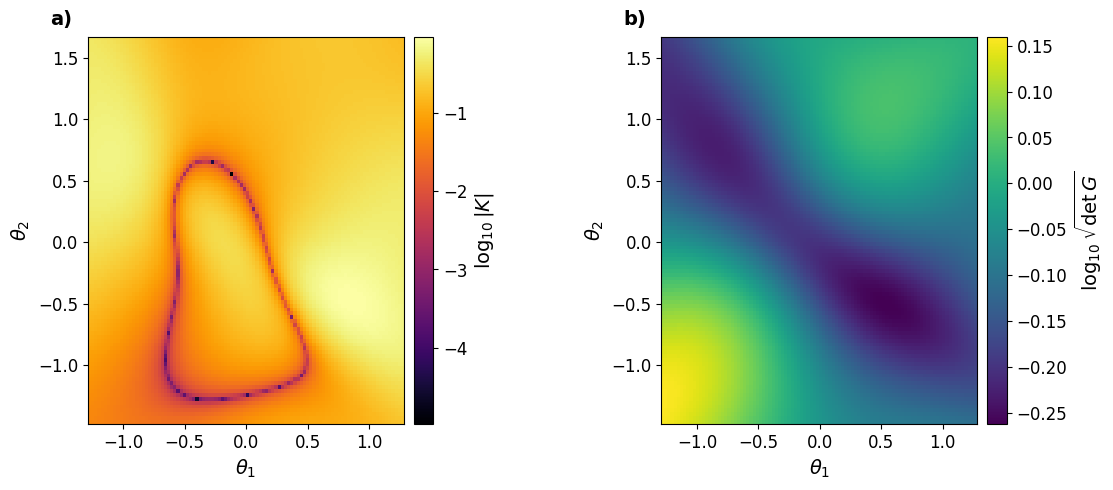

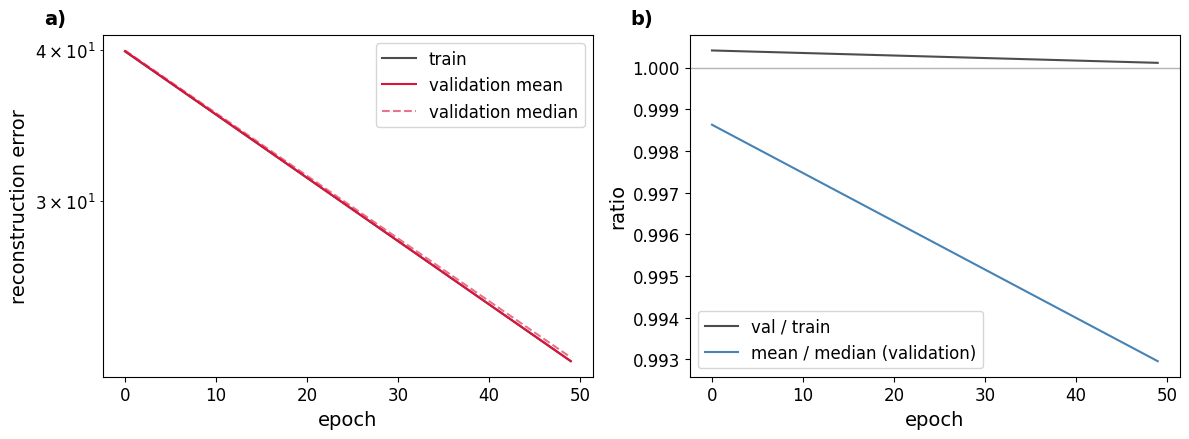

In [9]:
model, data, angles, curve, (val_x, val_ang) = run("smoketest", make_torus_dataset, 50, (True, True), "smoketest")
fig, c = plot_curve(curve, os.path.join(OUT, "flat on flat"))
print(c.tail(3))
#gb(model, data)


=== flat on flat  (flat plane)
epoch     0  loss=53.1925  recon=53.1701  kl=0.0224
epoch   100  loss=9.9248  recon=8.6332  kl=1.2916
epoch   200  loss=5.7556  recon=3.3953  kl=2.3603
epoch   300  loss=4.7634  recon=2.1722  kl=2.5913
epoch   400  loss=4.2578  recon=1.5167  kl=2.7411
epoch   500  loss=4.1057  recon=1.3287  kl=2.7770
epoch   600  loss=4.0166  recon=1.2184  kl=2.7982
epoch   700  loss=4.0090  recon=1.1972  kl=2.8118
epoch   800  loss=3.9439  recon=1.1273  kl=2.8166
epoch   900  loss=3.9319  recon=1.1187  kl=2.8132
epoch  1000  loss=3.9114  recon=1.0925  kl=2.8189
epoch  1100  loss=3.8949  recon=1.0684  kl=2.8265
epoch  1200  loss=3.8992  recon=1.0799  kl=2.8194
epoch  1300  loss=3.9020  recon=1.0824  kl=2.8196
epoch  1400  loss=3.8966  recon=1.0776  kl=2.8190
epoch  1500  loss=3.8573  recon=1.0323  kl=2.8250
epoch  1600  loss=3.8692  recon=1.0393  kl=2.8299
epoch  1700  loss=3.8805  recon=1.0473  kl=2.8332
epoch  1800  loss=3.8636  recon=1.0357  kl=2.8279
epoch  1900  los

(<Figure size 1200x550 with 3 Axes>,
 array([ 144, 1375, 1422, 1878,  450, 1577, 1862,  465, 1993,  546, 1817,
          73, 1014, 1357, 1237, 1287, 1439,  415, 1229,  102, 1391, 1828,
         622, 1526,  188, 1784, 1069, 1364, 1295,  482,  588,  859,  511,
        1731,  780,  202,  422,   10, 1158,  287,  359, 1552, 1110,  984,
        1007,  754, 1112,  153,   18,  602,  257,  755,  229,  923, 1302,
         609,   79, 1945,  471, 1948,  708, 1024,   78,  860,  711,  187,
         887, 1843,  681,  286,  399,   56,  353,  495, 1334,   99, 1449,
         110, 1727, 1186,  232,  174, 1947,  261,   37,  481,  136,  524,
          63, 1981,  885,  250,  492,  832,  255, 1632,  418, 1402,  116,
          49, 1038,  898,  410,  115, 1959, 1710,  942,  273, 1177,  954,
        1871,   59, 1265,   27,  670, 1123, 1969,  142,  325, 1827, 1472,
        1944,  130, 1875,  369,  615, 1892,  903, 1866, 1918, 1280,  366,
        1950, 1847, 1922,  881,  407, 1331,  485,  910,   42,  507,  233,
 

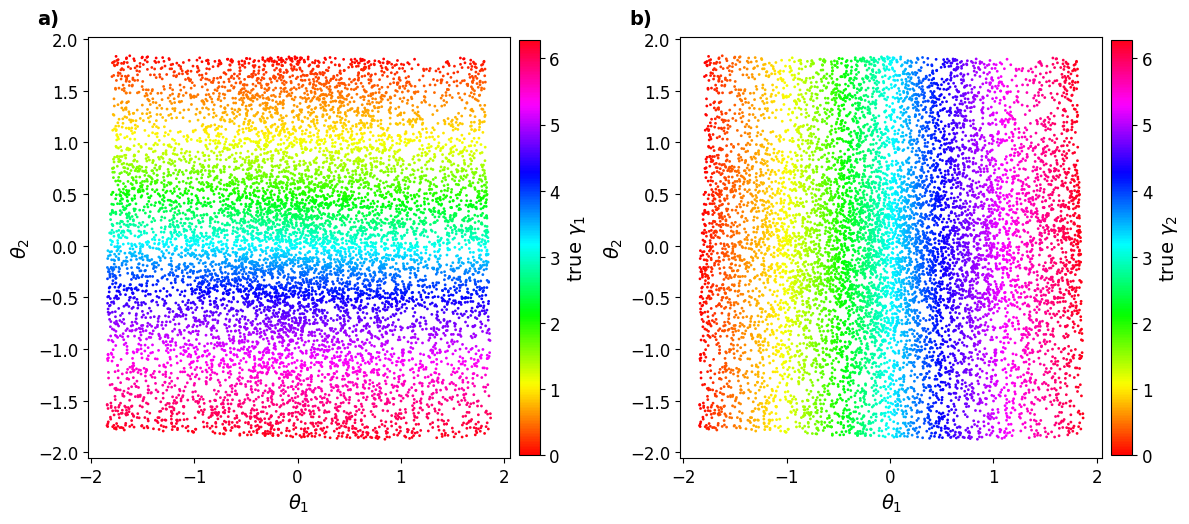

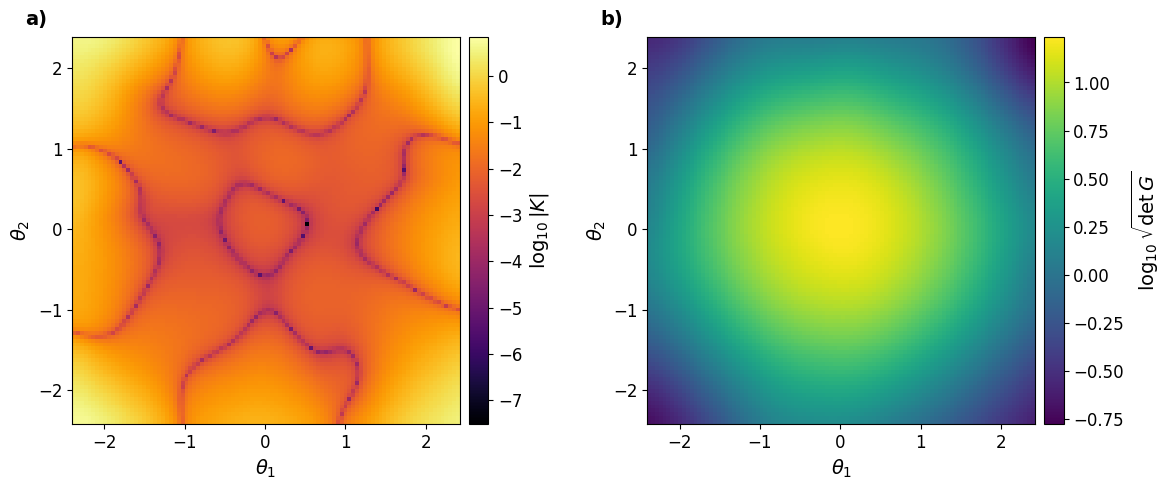

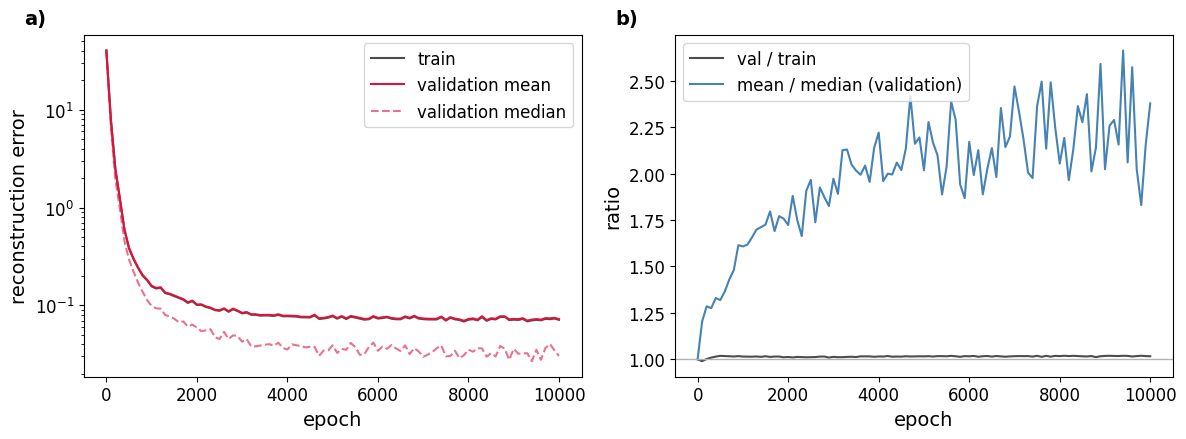

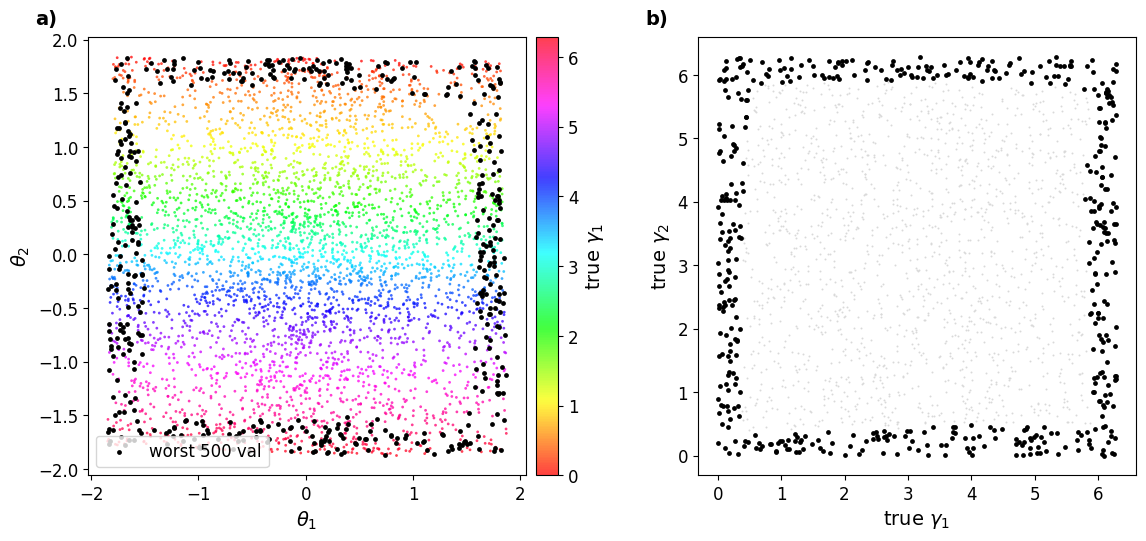

In [10]:
model, data, angles, curve, (val_x, val_ang) = run("flat on flat", make_plane_dataset_old, 10000, (True, True), "flat plane")
fig, c = plot_curve(curve, os.path.join(OUT, "flat on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "flat on flat"))


=== border flat on flat  (bordered flat plane)
epoch     0  loss=48.9592  recon=48.9473  kl=0.0119
epoch   100  loss=19.3015  recon=17.6843  kl=1.6171
epoch   200  loss=15.5034  recon=12.5986  kl=2.9048
epoch   300  loss=14.1521  recon=10.8634  kl=3.2887
epoch   400  loss=12.8011  recon=9.0363  kl=3.7648
epoch   500  loss=11.6794  recon=7.6289  kl=4.0506
epoch   600  loss=10.5631  recon=6.2978  kl=4.2653
epoch   700  loss=10.0032  recon=5.6874  kl=4.3158
epoch   800  loss=9.2611  recon=4.8444  kl=4.4166
epoch   900  loss=8.5271  recon=4.0162  kl=4.5109
epoch  1000  loss=7.9426  recon=3.3586  kl=4.5839
epoch  1100  loss=7.5906  recon=2.9721  kl=4.6185
epoch  1200  loss=7.3626  recon=2.7333  kl=4.6293
epoch  1300  loss=7.2033  recon=2.5685  kl=4.6348
epoch  1400  loss=7.0632  recon=2.4250  kl=4.6382
epoch  1500  loss=6.9207  recon=2.2722  kl=4.6485
epoch  1600  loss=6.8391  recon=2.1720  kl=4.6671
epoch  1700  loss=6.7671  recon=2.1014  kl=4.6657
epoch  1800  loss=6.6512  recon=1.9758  

{'area_term': 3.269085374109033,
 'boundary_term': 3.014696324158693,
 'total': 6.283781698267726,
 'residual': 0.0005963910881394696,
 'area': 924.7654725932305,
 'K_polar': array([[ 2.78500349e-03,  2.79519064e-03,  2.80518761e-03, ...,
          2.75218877e-03,  2.76362839e-03,  2.77452239e-03],
        [ 1.69963713e-03,  1.63208837e-03,  1.57663752e-03, ...,
          1.96668831e-03,  1.86791551e-03,  1.77854499e-03],
        [-7.64725857e-04, -9.56273737e-04, -1.11858849e-03, ...,
         -2.26887834e-05, -2.97280254e-04, -5.44825934e-04],
        ...,
        [-1.30398941e-01, -5.73634773e-02, -4.30086616e-02, ...,
         -2.07525538e-01, -2.05230147e-01, -1.88667384e-01],
        [-1.32700724e-01, -5.80238599e-02, -4.63382381e-02, ...,
         -2.11689366e-01, -2.06528655e-01, -1.90094052e-01],
        [-1.34335763e-01, -5.84153096e-02, -4.91995361e-02, ...,
         -2.14336265e-01, -2.06088055e-01, -1.89999460e-01]]),
 'V_polar': array([[193.91150039, 193.90932619, 193.901

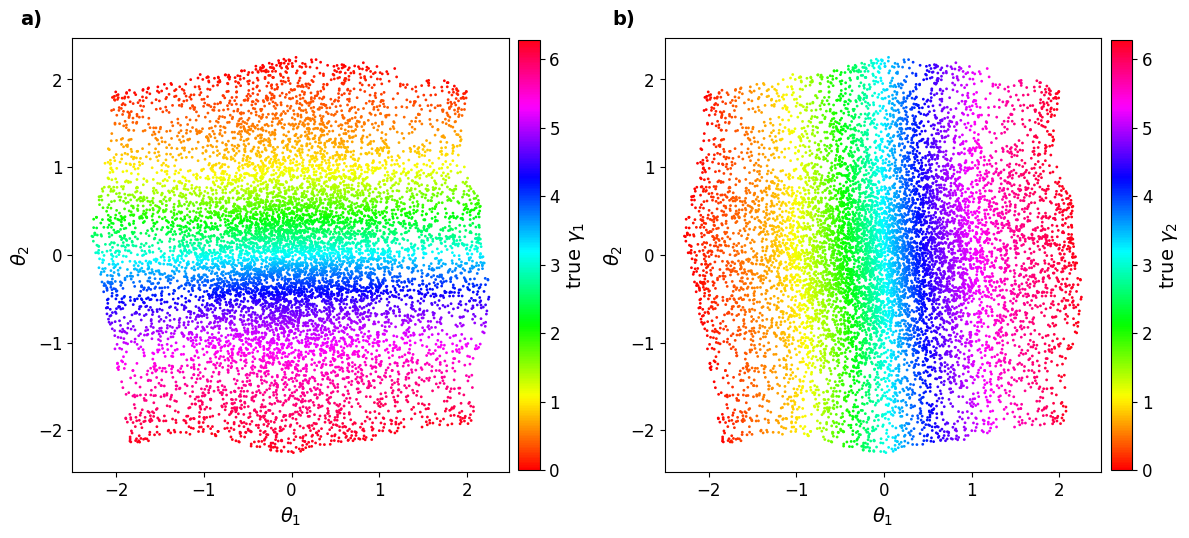

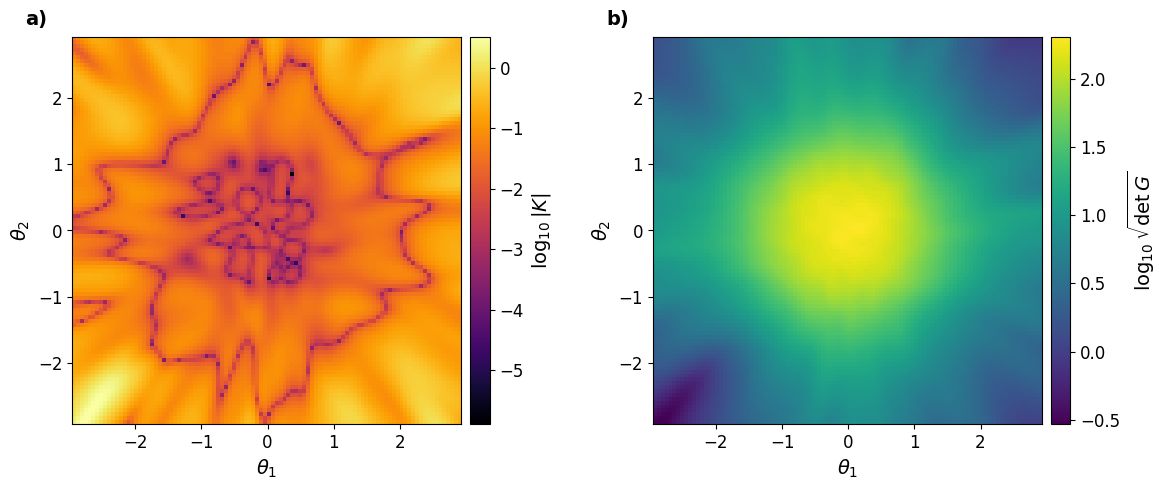

In [11]:
model, data, angles, curve, (val_x, val_ang) = run("border flat on flat", make_plane_dataset, 10000, (True, True), "bordered flat plane")
gb(model, data)


=== border flat on flat  (bordered flat plane)
epoch     0  loss=48.9592  recon=48.9473  kl=0.0119
epoch   100  loss=19.3015  recon=17.6843  kl=1.6171
epoch   200  loss=15.5034  recon=12.5986  kl=2.9048
epoch   300  loss=14.1521  recon=10.8634  kl=3.2887
epoch   400  loss=12.8011  recon=9.0363  kl=3.7648
epoch   500  loss=11.6794  recon=7.6289  kl=4.0506
epoch   600  loss=10.5631  recon=6.2978  kl=4.2653
epoch   700  loss=10.0032  recon=5.6874  kl=4.3158
epoch   800  loss=9.2611  recon=4.8444  kl=4.4166
epoch   900  loss=8.5271  recon=4.0162  kl=4.5109
epoch  1000  loss=7.9426  recon=3.3586  kl=4.5839
epoch  1100  loss=7.5906  recon=2.9721  kl=4.6185
epoch  1200  loss=7.3626  recon=2.7333  kl=4.6293
epoch  1300  loss=7.2033  recon=2.5685  kl=4.6348
epoch  1400  loss=7.0632  recon=2.4250  kl=4.6382
epoch  1500  loss=6.9207  recon=2.2722  kl=4.6485
epoch  1600  loss=6.8391  recon=2.1720  kl=4.6671
epoch  1700  loss=6.7671  recon=2.1014  kl=4.6657
epoch  1800  loss=6.6512  recon=1.9758  

(<Figure size 1200x550 with 3 Axes>,
 array([1416, 1257, 1376,  493, 1292, 1881, 1950, 1705, 1615, 1852,  647,
        1598,  370,  170, 1276, 1255, 1671,  503, 1061,  980,  670, 1258,
        1025, 1860,  848,  984, 1584,  572,  812, 1189, 1583, 1104,    6,
        1517,  271, 1413,  660, 1390, 1711,  328,  953, 1913, 1907,  221,
         342,  322,  900,  973,  530, 1281, 1691, 1051,   32,  928, 1826,
         518, 1224, 1578,   44, 1313, 1072, 1409, 1264, 1335,  231, 1984,
          66,  948,  559, 1944, 1923,  890,  849, 1143, 1999, 1058,  924,
         418, 1153, 1398, 1775, 1557,  309,  364, 1945, 1440,  960, 1022,
        1832,  501, 1926, 1694, 1123, 1176, 1450,  769,  438,  242,  516,
         399, 1410,  279,  145,  409, 1712,  630,  682,  641, 1773,  314,
         786,  874,  910, 1295,  146,  651, 1608,  460,  114,  880, 1019,
           9,  117, 1456, 1067, 1807, 1256, 1998, 1748,  792, 1794,  434,
         607,  511,  487,  789,  175, 1669, 1717,  534, 1901, 1858,  846,
 

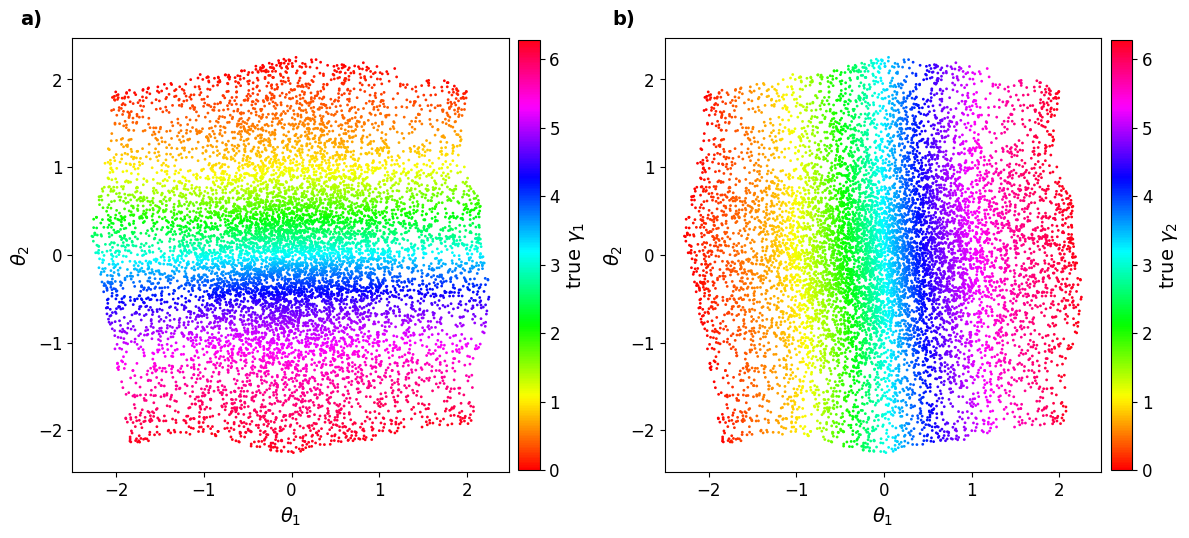

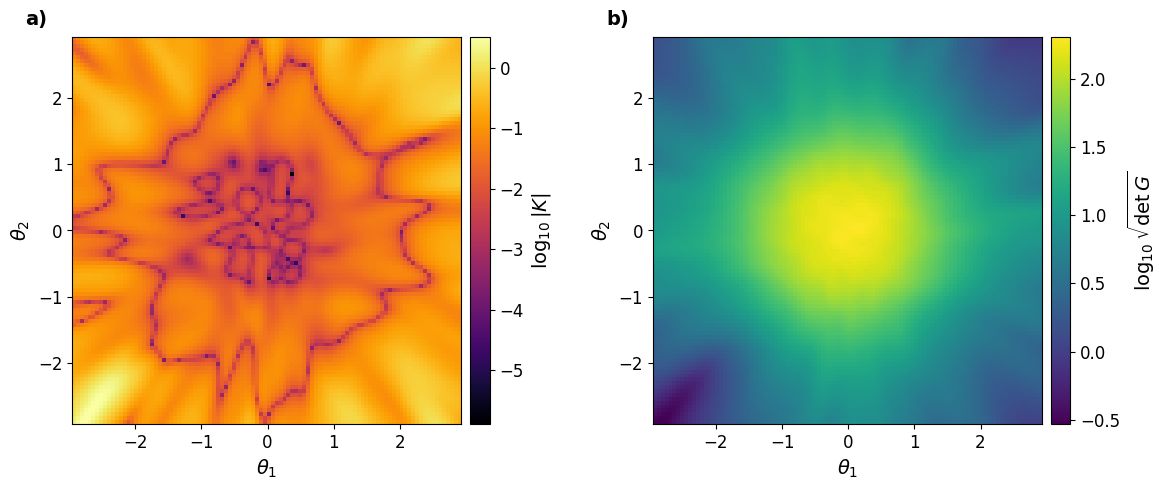

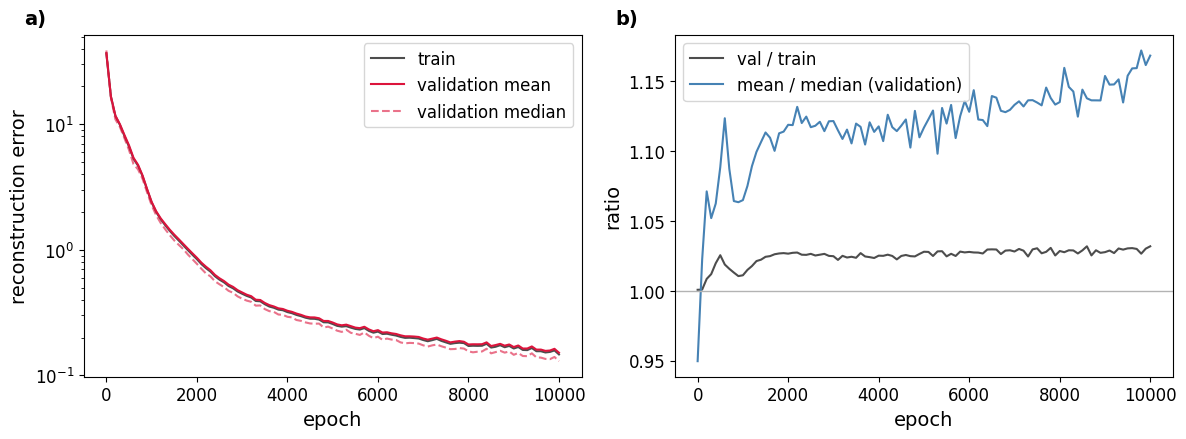

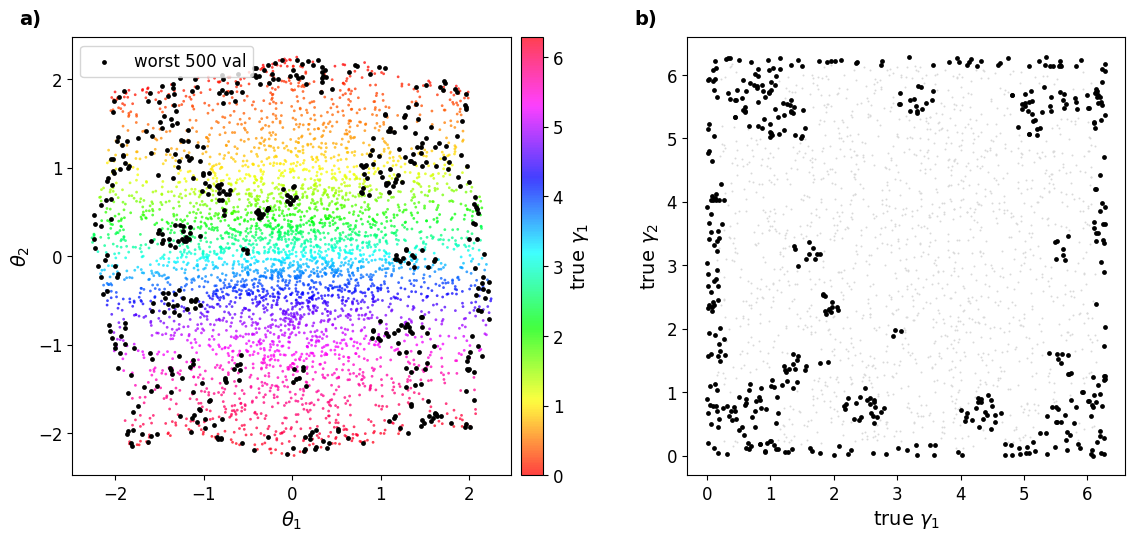

In [12]:
model, data, angles, curve, (val_x, val_ang) = run("border flat on flat", make_plane_dataset, 10000, (True, True), "bordered flat plane")
fig, c = plot_curve(curve, os.path.join(OUT, "border flat on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "border flat on flat"))



=== torus on flat  (torus)
epoch     0  loss=52.1704  recon=52.1580  kl=0.0124
epoch   100  loss=21.3402  recon=19.5669  kl=1.7733
epoch   200  loss=18.0384  recon=15.2121  kl=2.8264
epoch   300  loss=16.0959  recon=12.6875  kl=3.4084
epoch   400  loss=14.8079  recon=11.0172  kl=3.7906
epoch   500  loss=13.8302  recon=9.8291  kl=4.0011
epoch   600  loss=12.9968  recon=8.8513  kl=4.1455
epoch   700  loss=12.1555  recon=7.8387  kl=4.3168
epoch   800  loss=11.2804  recon=6.8287  kl=4.4517
epoch   900  loss=10.7069  recon=6.1663  kl=4.5406
epoch  1000  loss=10.2293  recon=5.6238  kl=4.6055
epoch  1100  loss=9.8174  recon=5.1557  kl=4.6618
epoch  1200  loss=9.4610  recon=4.7540  kl=4.7070
epoch  1300  loss=9.1770  recon=4.4242  kl=4.7527
epoch  1400  loss=8.8917  recon=4.1096  kl=4.7822
epoch  1500  loss=8.6039  recon=3.7882  kl=4.8157
epoch  1600  loss=8.4346  recon=3.5812  kl=4.8534
epoch  1700  loss=8.2602  recon=3.3965  kl=4.8637
epoch  1800  loss=8.1006  recon=3.2121  kl=4.8885
epoch 

{'area_term': -7.342877263924789,
 'boundary_term': 14.052737326294524,
 'total': 6.709860062369735,
 'residual': 0.42667475519014886,
 'area': 1406.40990274125,
 'K_polar': array([[ 0.04987017,  0.05149358,  0.05311799, ...,  0.04507021,
          0.04665235,  0.04825433],
        [ 0.03153276,  0.04185956,  0.05234672, ...,  0.00272531,
          0.01183472,  0.02148208],
        [-0.18620909, -0.15343357, -0.12297403, ..., -0.30217651,
         -0.26023297, -0.22168468],
        ...,
        [ 0.00087419, -0.07028046, -0.14316154, ..., -0.02959303,
         -0.01908262,  0.00533491],
        [ 0.0026026 , -0.07508993, -0.15163598, ..., -0.03185125,
         -0.01930372,  0.00771755],
        [ 0.00401143, -0.08014285, -0.15904751, ..., -0.03422989,
         -0.01961928,  0.00991155]]),
 'V_polar': array([[182.76348649, 182.66667006, 182.61805703, ..., 183.35666772,
         183.10728488, 182.90993053],
        [134.94618243, 136.17138485, 137.48596796, ..., 132.01418404,
         13

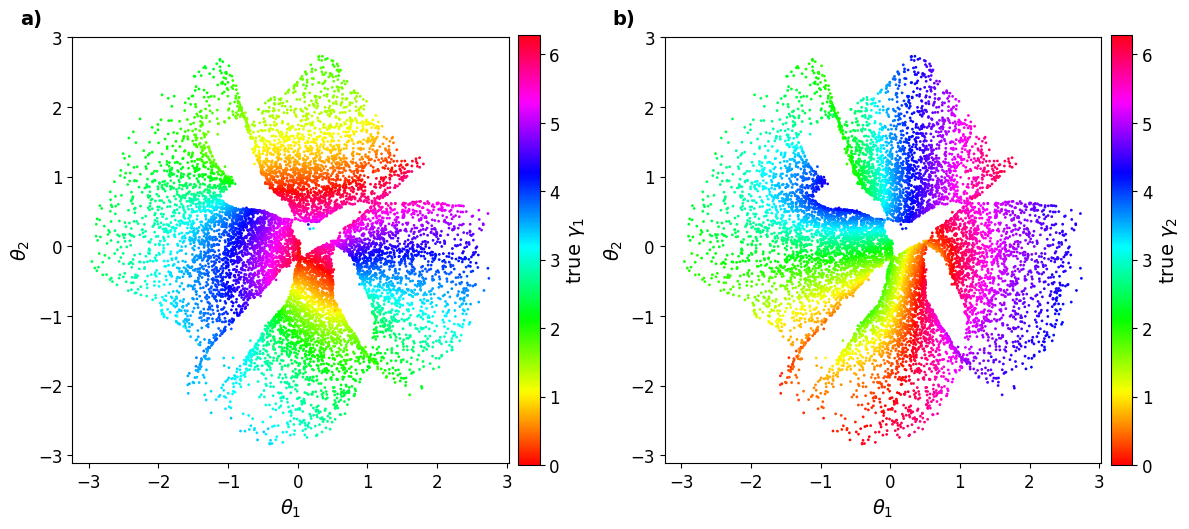

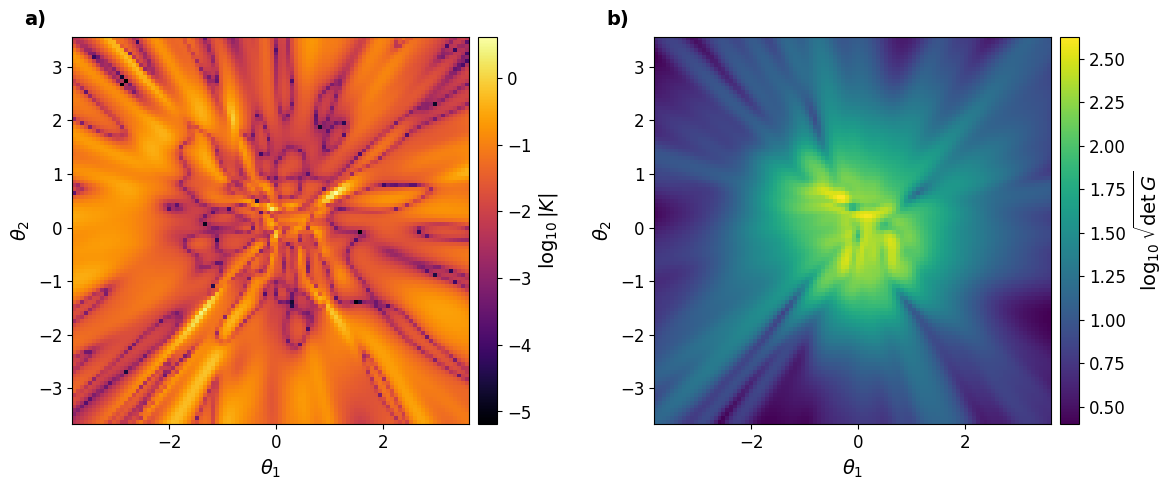

In [13]:
model, data, angles, curve, (val_x, val_ang) = run("torus on flat", make_torus_dataset, 10000, (True, True), "torus")
gb(model, data)


=== torus on flat  (torus)
epoch     0  loss=52.1704  recon=52.1580  kl=0.0124
epoch   100  loss=21.3402  recon=19.5669  kl=1.7733
epoch   200  loss=18.0384  recon=15.2121  kl=2.8264
epoch   300  loss=16.0959  recon=12.6875  kl=3.4084
epoch   400  loss=14.8079  recon=11.0172  kl=3.7906
epoch   500  loss=13.8302  recon=9.8291  kl=4.0011
epoch   600  loss=12.9968  recon=8.8513  kl=4.1455
epoch   700  loss=12.1555  recon=7.8387  kl=4.3168
epoch   800  loss=11.2804  recon=6.8287  kl=4.4517
epoch   900  loss=10.7069  recon=6.1663  kl=4.5406
epoch  1000  loss=10.2293  recon=5.6238  kl=4.6055
epoch  1100  loss=9.8174  recon=5.1557  kl=4.6618
epoch  1200  loss=9.4610  recon=4.7540  kl=4.7070
epoch  1300  loss=9.1770  recon=4.4242  kl=4.7527
epoch  1400  loss=8.8917  recon=4.1096  kl=4.7822
epoch  1500  loss=8.6039  recon=3.7882  kl=4.8157
epoch  1600  loss=8.4346  recon=3.5812  kl=4.8534
epoch  1700  loss=8.2602  recon=3.3965  kl=4.8637
epoch  1800  loss=8.1006  recon=3.2121  kl=4.8885
epoch 

(<Figure size 1200x550 with 3 Axes>,
 array([1054, 1666,  143,  260, 1771, 1626,  656, 1926, 1039,  501,  403,
         384,  560,  218, 1482, 1220, 1256, 1655,  518, 1578, 1301,  609,
         169,  153,  968,  483,  513,  102,    1, 1728, 1999, 1971, 1623,
        1175, 1772,   44,  502,   90,  767, 1030,  661, 1910, 1026, 1005,
         788,  864,  320,  878,   49,   47, 1072,  311,  818, 1118, 1556,
        1820, 1586,  414, 1214, 1668, 1865,  186, 1308,  684,   58,  761,
         879,  444,  171, 1209, 1873,  344, 1571,   59,  167, 1634, 1058,
        1356,  147, 1566, 1009,  441,  956, 1813,   85,  786, 1044, 1696,
        1841, 1708, 1186, 1104, 1883,  751, 1145,  480, 1420, 1877,  745,
        1591,  710, 1458,  691, 1731,  840, 1745, 1478, 1685, 1275, 1598,
        1744, 1441, 1322,  771,   46,   83, 1791,  290,  890,  693,  241,
         111,  292,  931,   38,  326, 1236,  355, 1409,  500, 1065,  428,
         601,  770, 1681, 1068, 1835,   96, 1766,  192,  904,  409,  682,
 

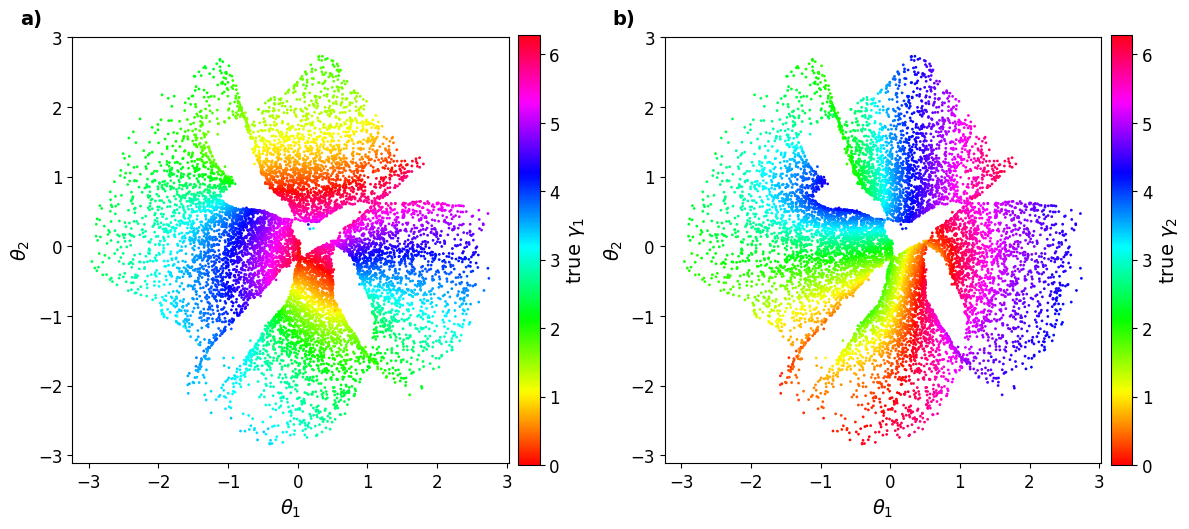

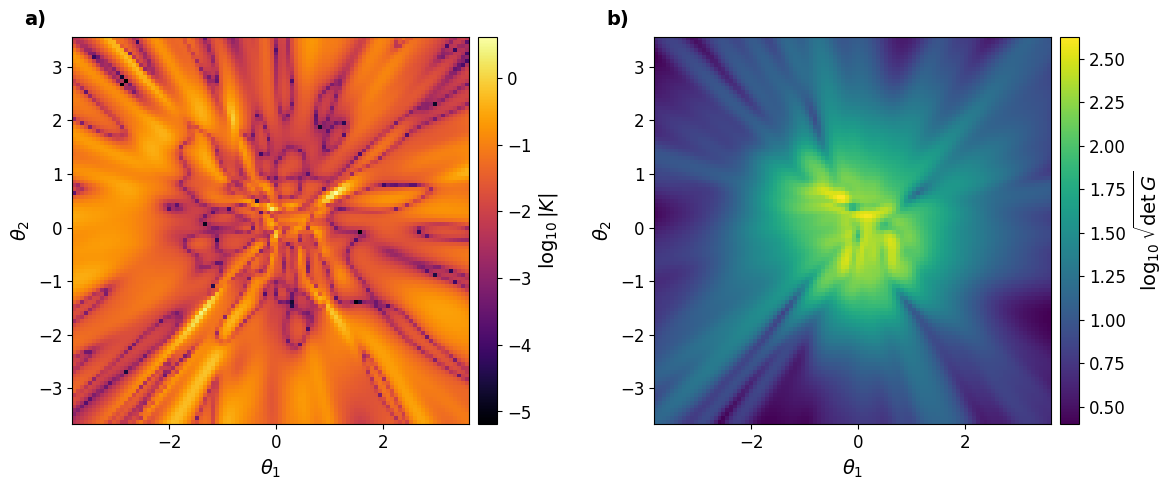

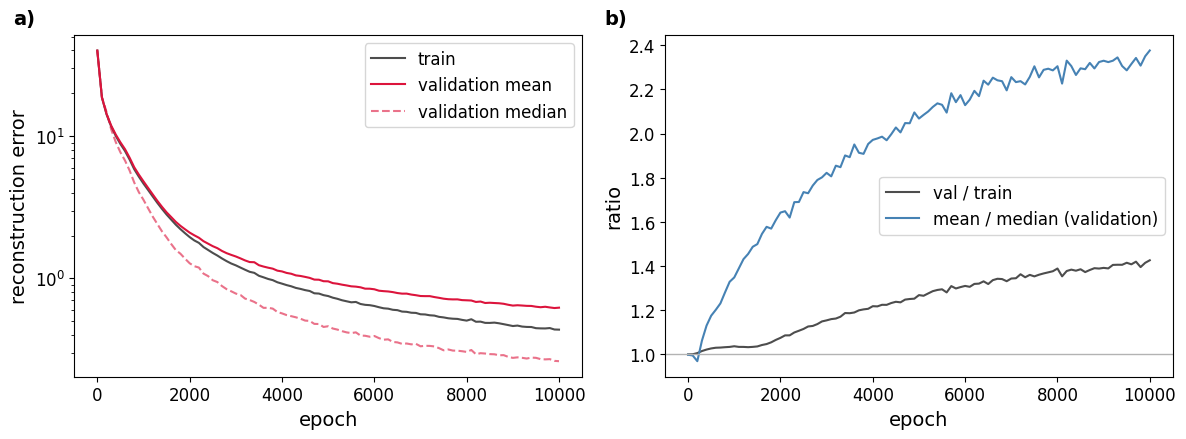

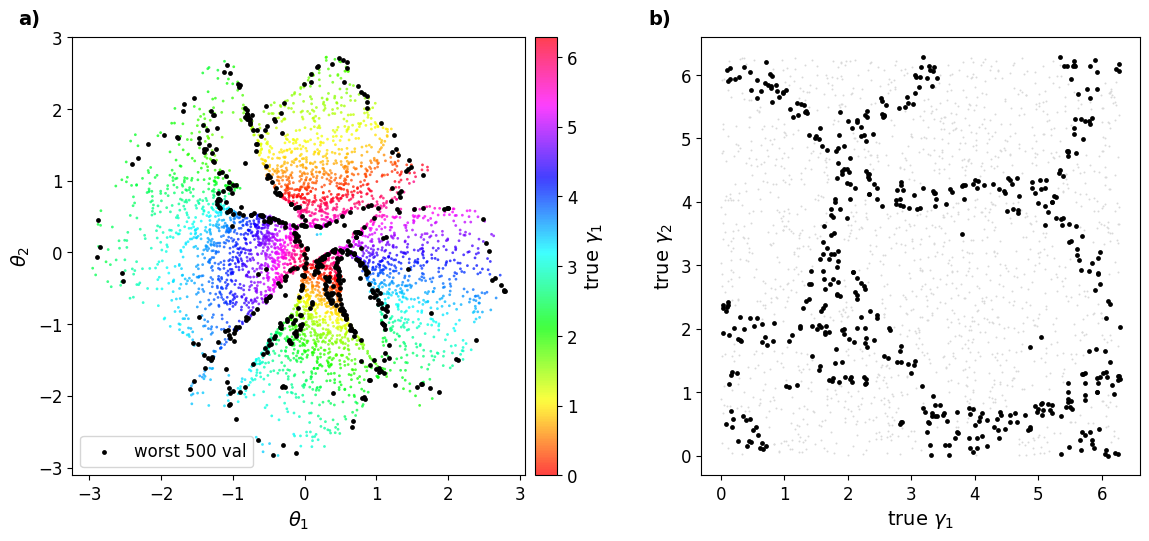

In [14]:
model, data, angles, curve, (val_x, val_ang) = run("torus on flat", make_torus_dataset, 10000, (True, True), "torus")
fig, c = plot_curve(curve, os.path.join(OUT, "torus on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "torus on flat"))



=== sphere on flat  (sphere)
epoch     0  loss=45.8264  recon=45.8149  kl=0.0114
epoch   100  loss=17.7638  recon=16.8049  kl=0.9588
epoch   200  loss=15.6333  recon=14.3333  kl=1.3000
epoch   300  loss=15.0977  recon=13.5833  kl=1.5144
epoch   400  loss=13.4581  recon=11.0219  kl=2.4362
epoch   500  loss=12.7081  recon=9.8834  kl=2.8247
epoch   600  loss=12.3096  recon=9.3076  kl=3.0020
epoch   700  loss=11.9987  recon=8.8348  kl=3.1639
epoch   800  loss=11.7416  recon=8.5039  kl=3.2377
epoch   900  loss=11.4925  recon=8.1677  kl=3.3248
epoch  1000  loss=10.8932  recon=7.3261  kl=3.5671
epoch  1100  loss=10.1224  recon=6.3503  kl=3.7720
epoch  1200  loss=9.3890  recon=5.4279  kl=3.9611
epoch  1300  loss=8.7232  recon=4.6153  kl=4.1079
epoch  1400  loss=8.2559  recon=4.0468  kl=4.2091
epoch  1500  loss=7.9203  recon=3.6443  kl=4.2759
epoch  1600  loss=7.6847  recon=3.3462  kl=4.3385
epoch  1700  loss=7.4963  recon=3.1240  kl=4.3723
epoch  1800  loss=7.2996  recon=2.8719  kl=4.4277
epo

{'area_term': -1.6358519241582865,
 'boundary_term': 7.921417712936497,
 'total': 6.285565788778211,
 'residual': 0.002380481598624584,
 'area': 1043.3208340915878,
 'K_polar': array([[ 3.62179493e-03,  3.60190556e-03,  3.58993140e-03, ...,
          3.73093058e-03,  3.68614296e-03,  3.64981334e-03],
        [-3.26765168e-03, -3.15001198e-03, -3.01920207e-03, ...,
         -3.52507378e-03, -3.45699554e-03, -3.37055373e-03],
        [-5.50272385e-04, -2.32907880e-04,  8.74804011e-05, ...,
         -1.48096235e-03, -1.17419644e-03, -8.64061210e-04],
        ...,
        [-2.48539970e-02, -3.65586436e-02, -5.99063575e-02, ...,
          4.20742619e-03, -1.00326969e-03, -1.17722637e-02],
        [-2.49893719e-02, -3.53413691e-02, -5.87901166e-02, ...,
          6.55689580e-03, -2.93795328e-05, -1.18043244e-02],
        [-2.51567453e-02, -3.41112339e-02, -5.75404205e-02, ...,
          8.91136356e-03,  8.47471214e-04, -1.19223132e-02]]),
 'V_polar': array([[118.69177876, 118.67895103, 118.6

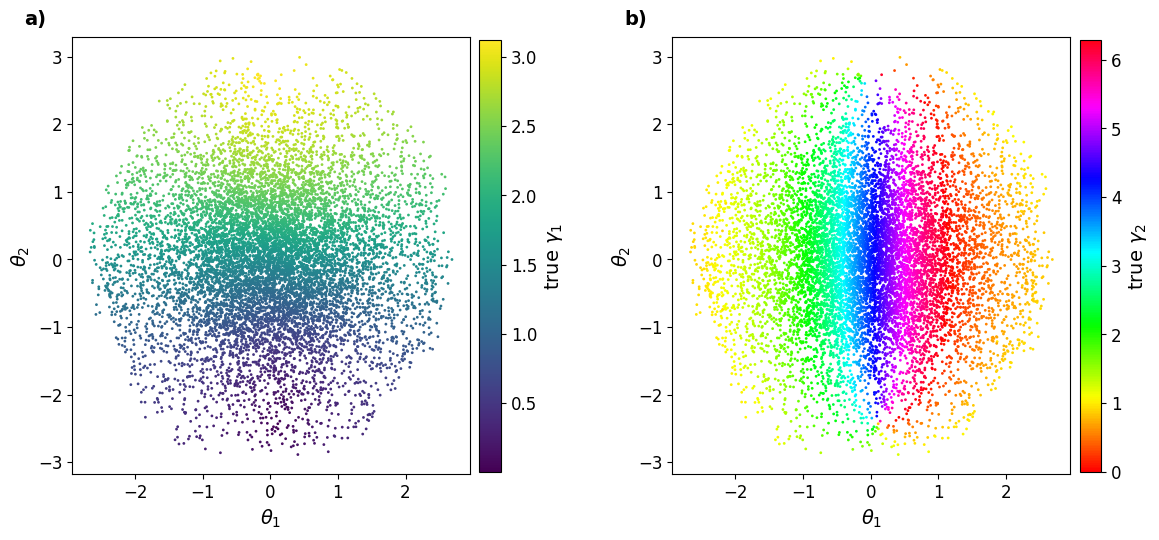

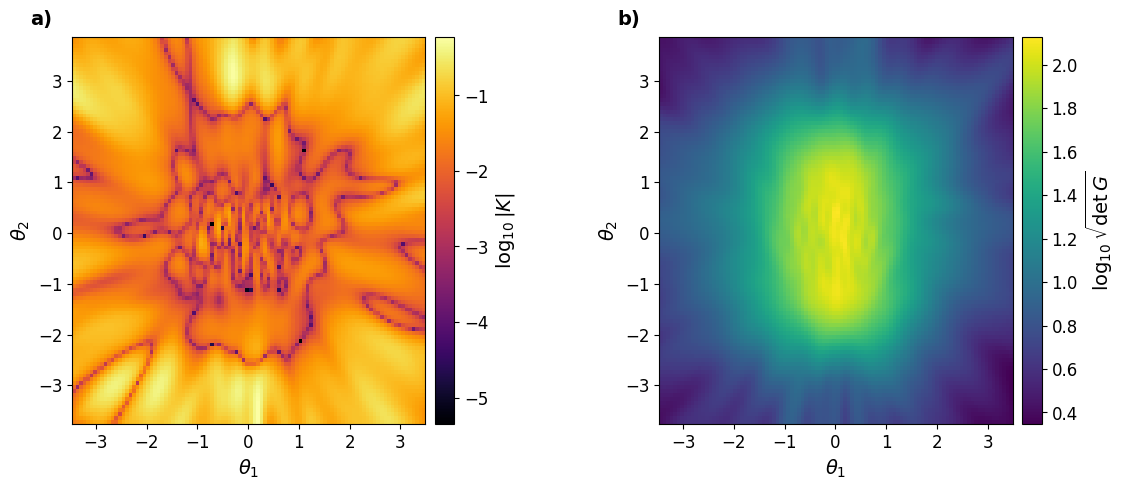

In [15]:
model, data, angles, curve, (val_x, val_ang) = run("sphere on flat", make_sphere_dataset_try3, 10000, (False, True), "sphere")
gb(model, data)


=== sphere on flat  (sphere)
epoch     0  loss=45.8264  recon=45.8149  kl=0.0114
epoch   100  loss=17.7638  recon=16.8049  kl=0.9588
epoch   200  loss=15.6333  recon=14.3333  kl=1.3000
epoch   300  loss=15.0977  recon=13.5833  kl=1.5144
epoch   400  loss=13.4581  recon=11.0219  kl=2.4362
epoch   500  loss=12.7081  recon=9.8834  kl=2.8247
epoch   600  loss=12.3096  recon=9.3076  kl=3.0020
epoch   700  loss=11.9987  recon=8.8348  kl=3.1639
epoch   800  loss=11.7416  recon=8.5039  kl=3.2377
epoch   900  loss=11.4925  recon=8.1677  kl=3.3248
epoch  1000  loss=10.8932  recon=7.3261  kl=3.5671
epoch  1100  loss=10.1224  recon=6.3503  kl=3.7720
epoch  1200  loss=9.3890  recon=5.4279  kl=3.9611
epoch  1300  loss=8.7232  recon=4.6153  kl=4.1079
epoch  1400  loss=8.2559  recon=4.0468  kl=4.2091
epoch  1500  loss=7.9203  recon=3.6443  kl=4.2759
epoch  1600  loss=7.6847  recon=3.3462  kl=4.3385
epoch  1700  loss=7.4963  recon=3.1240  kl=4.3723
epoch  1800  loss=7.2996  recon=2.8719  kl=4.4277
epo

(<Figure size 1200x550 with 3 Axes>,
 array([ 656, 1359,  808,  772,   83, 1602,  343,  805, 1057, 1677, 1504,
         988,  964, 1612,   10, 1753,  625, 1095, 1673,  752,  145,   99,
         130,  515, 1938,  936,   94, 1738, 1995,  882, 1374,  530,  199,
        1028,  938,  269, 1065, 1195,  500, 1980,   85, 1635, 1360, 1506,
        1921, 1861, 1055,  319, 1040, 1821, 1540,  908, 1651, 1690,  474,
        1160, 1141,  283, 1413, 1478, 1747, 1704, 1637,  186, 1623,   47,
        1343, 1487,  955, 1803,  235,  403,  542,  924,  152, 1324,   14,
         120,  335, 1614, 1123,  685,  762, 1603,  581,  730,  444,  456,
        1256,  180,  948,  607, 1043,  567,  650, 1895, 1306,  200, 1278,
        1584,  895, 1163, 1216, 1307, 1051, 1412, 1889,  570,  869,   96,
        1925,  282, 1833, 1379, 1962, 1766,  291, 1266, 1963,  933,  481,
         372,  367, 1370,  302, 1408,   68, 1783, 1465, 1809,  462,  329,
        1372, 1025,  166,  702,  876, 1274,  652, 1304, 1813, 1308,  683,
 

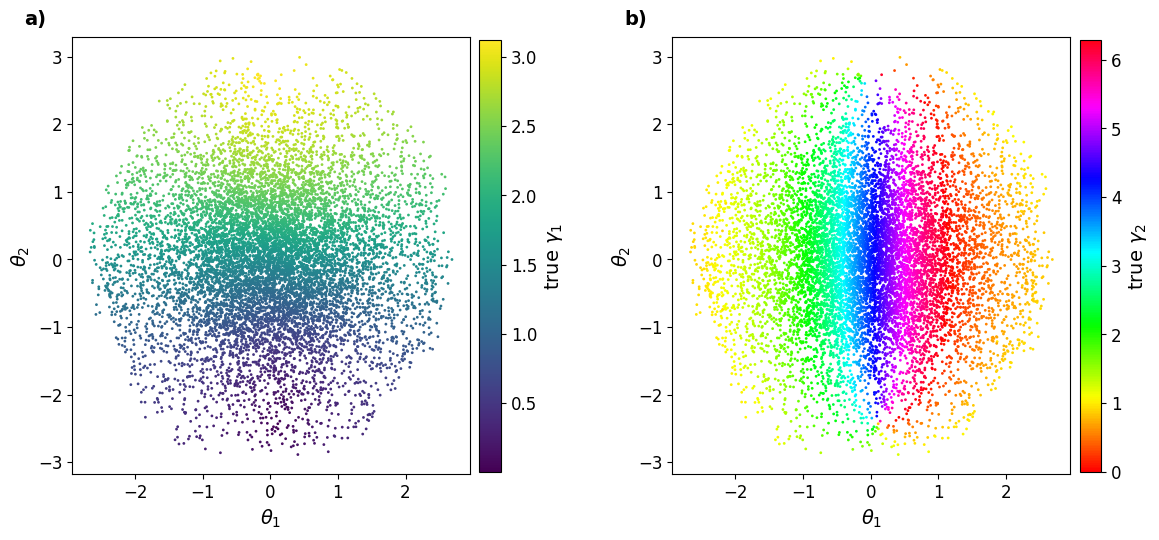

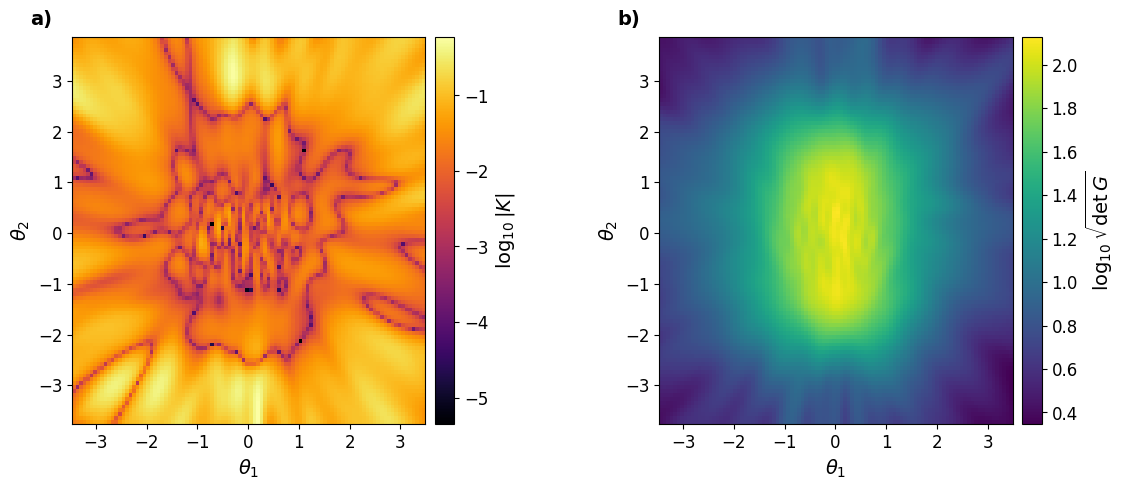

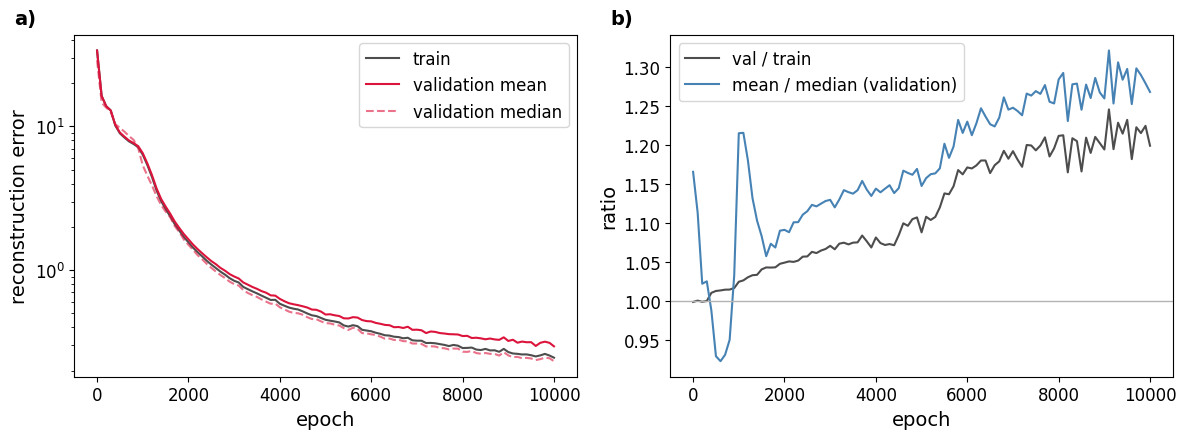

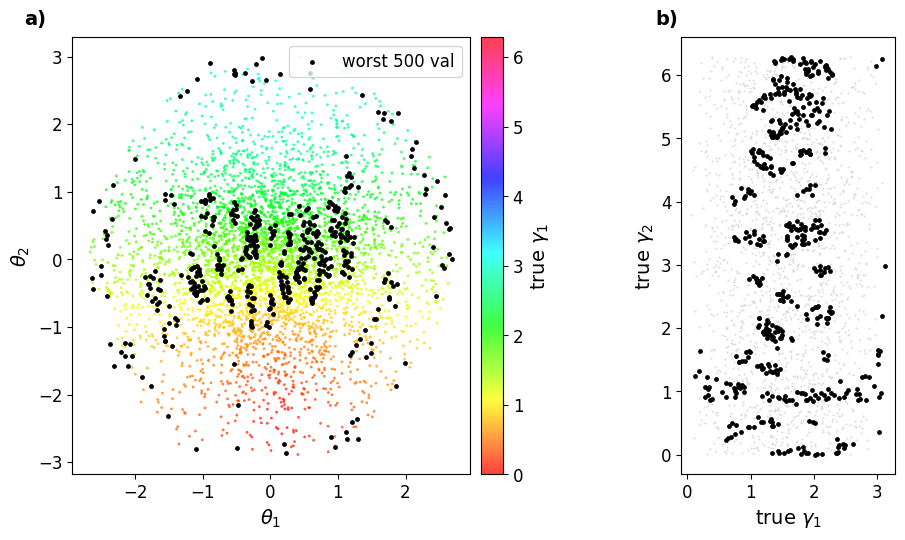

In [16]:
model, data, angles, curve, (val_x, val_ang) = run("sphere on flat", make_sphere_dataset_try3, 10000, (False, True), "sphere")
fig, c = plot_curve(curve, os.path.join(OUT, "sphere on flat"))
print(c.tail(3))
plot_worst_points(model, data, angles, val_x, val_ang,
                  save=os.path.join(OUT, "sphere on flat"))

     epoch      loss     recon        kl     train       val  val_median  \
98    9800  5.996305  1.259562  4.736743  0.261893  0.318378    0.246762   
99    9900  5.978446  1.256366  4.722080  0.255211  0.312633    0.244322   
100   9999  5.975714  1.227298  4.748416  0.246425  0.295582    0.233020   

      val_p95  
98   0.436166  
99   0.415304  
100  0.406027  


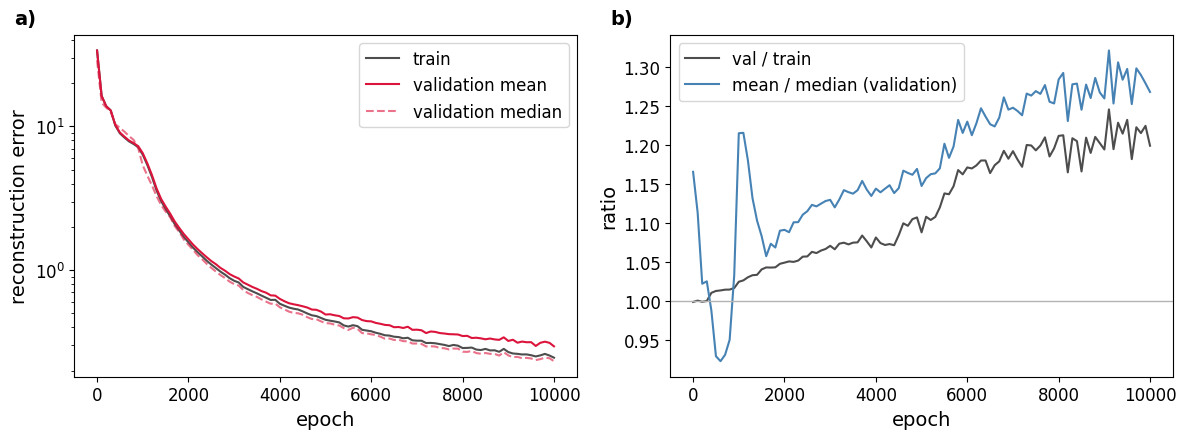

In [17]:
fig, c = plot_curve(curve, os.path.join(OUT, "sphere on flat"))
print(c.tail(3))


=== sphere on flat small 1  (sphere)
epoch     0  loss=45.8264  recon=45.8149  kl=0.0114
epoch   100  loss=17.7638  recon=16.8049  kl=0.9588
epoch   200  loss=15.6333  recon=14.3333  kl=1.3000
epoch   300  loss=15.0977  recon=13.5833  kl=1.5144
epoch   400  loss=13.4581  recon=11.0219  kl=2.4362
epoch   500  loss=12.7081  recon=9.8834  kl=2.8247
epoch   600  loss=12.3096  recon=9.3076  kl=3.0020
epoch   700  loss=11.9987  recon=8.8348  kl=3.1639
epoch   749  loss=11.8587  recon=8.6525  kl=3.2062
    trained in 4s
  |K|  : median 6.476e-03   max 1.571e-01
  sqrt(det g): median 8.259e+00   max 1.761e+01
    wrote sphere on flat small 1_latent.pdf and sphere on flat small 1_curvature.pdf
    done in 22s

=== sphere on flat mall 2  (sphere)
epoch     0  loss=45.8264  recon=45.8149  kl=0.0114
epoch   100  loss=17.7638  recon=16.8049  kl=0.9588
epoch   200  loss=15.6333  recon=14.3333  kl=1.3000
epoch   300  loss=15.0977  recon=13.5833  kl=1.5144
epoch   400  loss=13.4581  recon=11.0219  kl

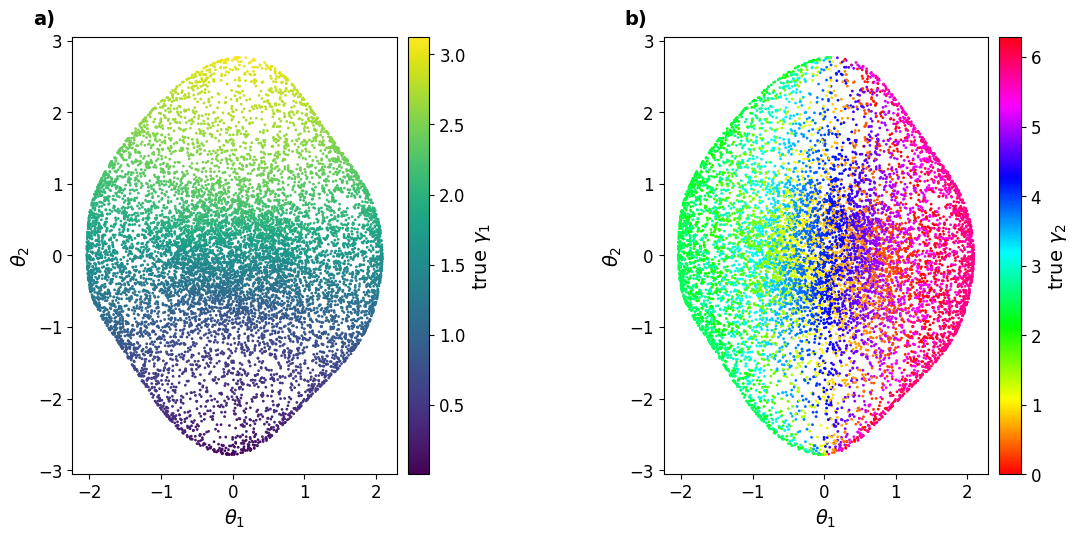

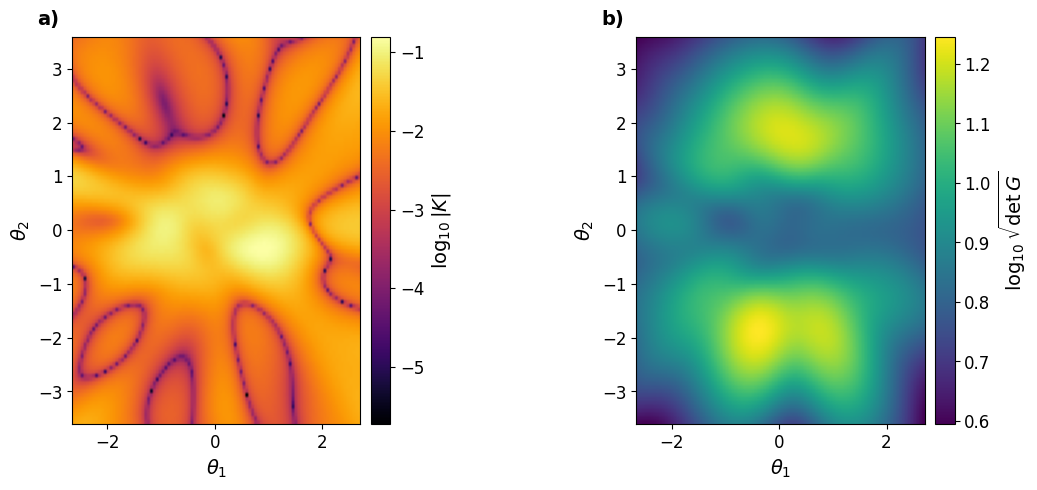

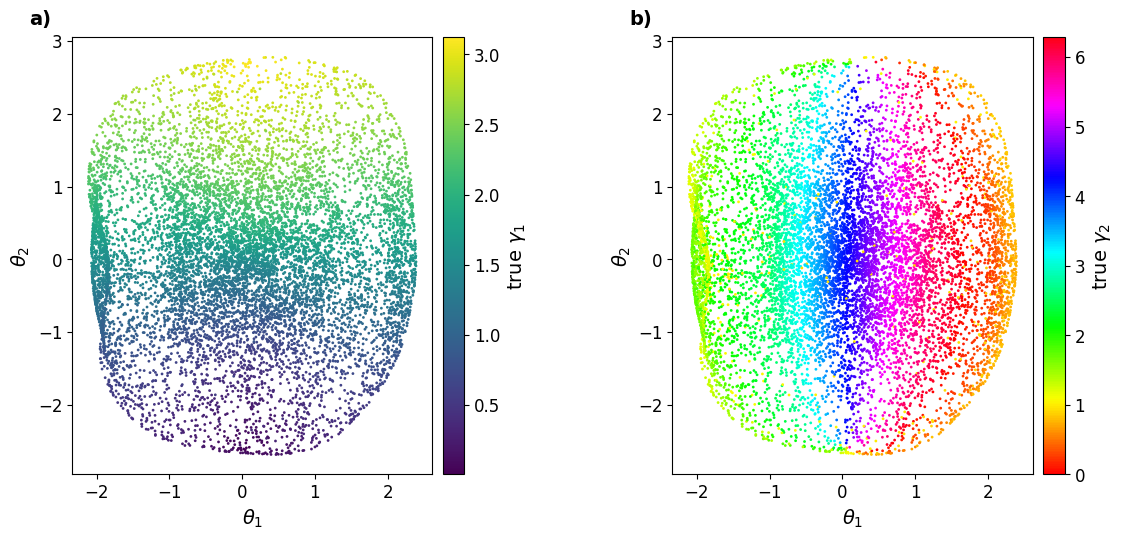

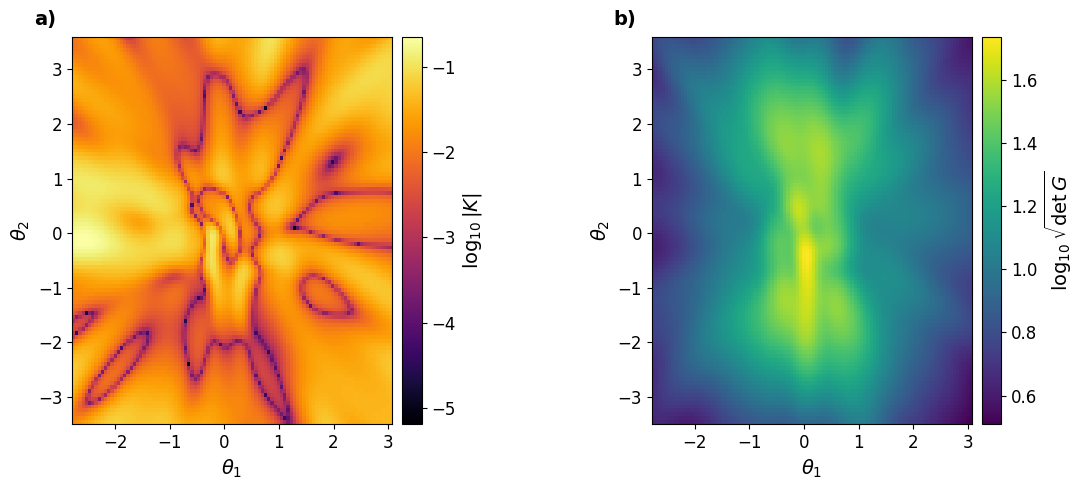

In [18]:
model, data, angles, figs, curve = run("sphere on flat small 1", make_sphere_dataset_try3, 750, (False, True), "sphere")
model, data, angles, figs, curve = run("sphere on flat mall 2", make_sphere_dataset_try3, 1250, (False, True), "sphere")
